In [130]:
import SimpleITK as sitk 
from pathlib import Path
import numpy as np
import pickle
import sys
sys.path.append('../scripts')
import gpa
import vtk
import numpy as np
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

In [131]:
base_folder = Path(r"/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp")
stat_file = base_folder / "combined_skull_analysis.csv"


In [132]:
stat_df = pd.read_csv(stat_file,index_col='Unnamed: 0')
labels = stat_df
stat_df.dropna().sort_values(by='percentage of 99%')

,GENDER,COHORT_ID,DATE,VALUE_CATEGORY,Procrustes Distance,abnormal shape computer,percentage of 99%
wt_M_82Z-13914,male,c300,2023-08-07,abnormal,473.954960,normal,0.000000
Impact_M_E64-CC306,male,c273,2023-01-16,normal,418.756714,normal,0.000000
wt_F_82Z-CH420,female,c284,2023-04-03,normal,539.675835,normal,0.000000
wt_M_82Z-12615,male,c284,2023-04-03,normal,386.027255,normal,0.000000
wt_M_82Z-CH430,male,c285,2023-04-11,abnormal,284.456648,normal,0.000000
...,...,...,...,...,...,...,...
wt_F_82Z-11542,female,c267,2022-12-05,normal,1805.058547,abnormal,0.997175
Fam161b_F_E64-H0175,female,c267,2022-12-05,normal,72135.750621,abnormal,0.998444
wt_F_82Z-11544,female,c267,2022-12-05,normal,357580.661834,abnormal,0.998444
Fam161b_F_E64-H0172,female,c267,2022-12-05,normal,137042.188407,abnormal,0.999174


<AxesSubplot:title={'center':'Procrustes Distance'}, xlabel='[VALUE_CATEGORY]'>

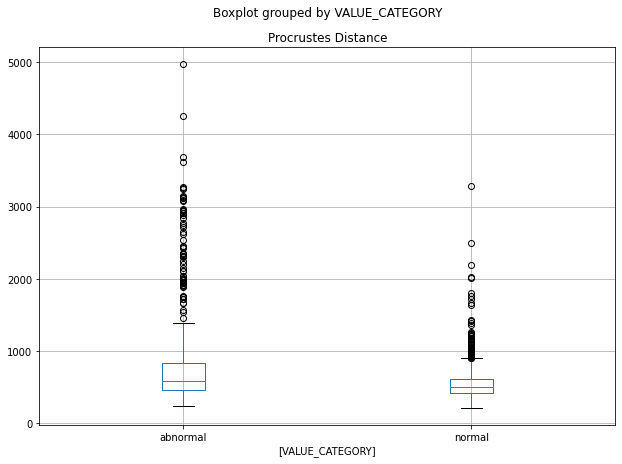

In [133]:
labels[['Procrustes Distance','VALUE_CATEGORY']].dropna().loc[labels['Procrustes Distance']<5000].boxplot(by='VALUE_CATEGORY',figsize=(10,7))

In [134]:
stat_df.describe()

,Procrustes Distance,percentage of 99%
count,1630.000000,1630.000000
mean,1165.060137,0.037016
std,10772.660030,0.126858
min,218.461700,0.000000
25%,433.543689,0.000442
50%,520.868878,0.003190
75%,653.706463,0.014214
max,357580.661834,0.999962


In [135]:
model_for = labels[['Procrustes Distance','VALUE_CATEGORY']].loc[labels['Procrustes Distance']<5000]
model_for = model_for.dropna()
x = range(500,2000,10)
true_p = []
all_p = []
all_neg = []
true_neg = []
for frob in x: 
    
    tmp_ab = model_for.loc[model_for['Procrustes Distance'] >= frob ]
    t_all_pos = len(tmp_ab) #all detected positives(as abnormals) 
    t_true_pos = len(tmp_ab.loc[tmp_ab['VALUE_CATEGORY']=='abnormal']) # correctly identified
    tmp_ab = model_for.loc[model_for['Procrustes Distance'] < frob ]
    t_true_neg = len(tmp_ab.loc[tmp_ab['VALUE_CATEGORY']=='normal'])
    t_all_neg = len(tmp_ab)
    true_p.append(t_true_pos)
    all_p.append(t_all_pos)
    all_neg.append(t_all_neg)
    true_neg.append(t_true_neg)
#    break
model_for = pd.DataFrame()
model_for['tp'] = true_p
model_for['ap'] = all_p
model_for['an'] = all_neg
model_for['tn'] = true_neg
model_for['sensitivity'] = model_for['tp'] / model_for['ap']
model_for['specificity'] = model_for['tn'] / model_for['an']
model_for['accuracy'] = (model_for['tp'] +model_for['tn']) / (model_for['an'] + model_for['ap'])
model_for.index = x

<AxesSubplot:>

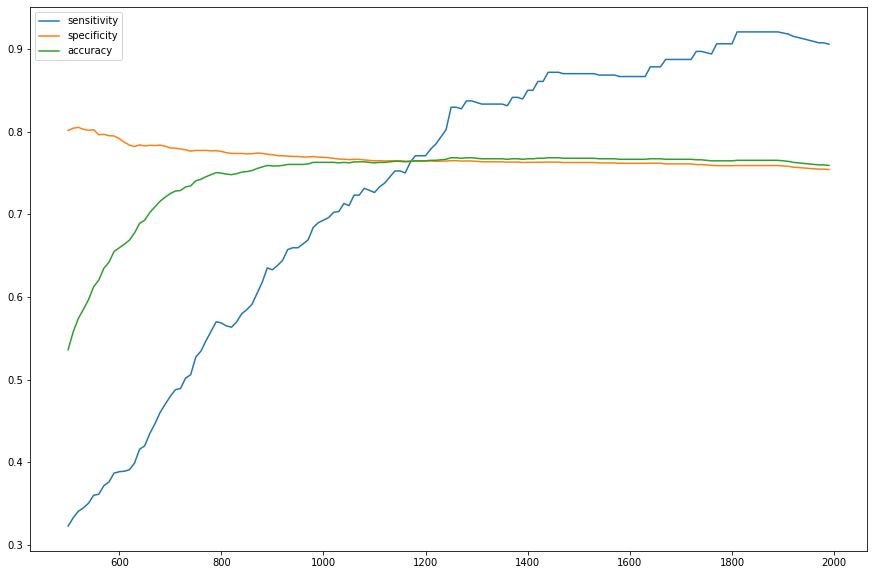

In [136]:
model_for[['sensitivity','specificity','accuracy']].plot(figsize=(15,10))

In [137]:
x = pd.DataFrame()
x['a'] = list(range(100))
x

,a
0,0
1,1
2,2
3,3
4,4
...,...
95,95
96,96
97,97
98,98


<AxesSubplot:title={'center':'percentage of 99%'}, xlabel='[VALUE_CATEGORY]'>

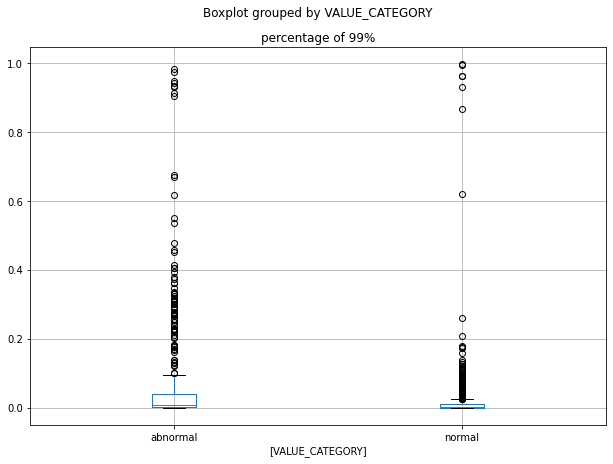

In [138]:
labels[['percentage of 99%','VALUE_CATEGORY']].dropna().loc[labels['Procrustes Distance']<5000].boxplot(by='VALUE_CATEGORY',figsize=(10,7))

In [139]:
labels

,GENDER,COHORT_ID,DATE,VALUE_CATEGORY,Procrustes Distance,abnormal shape computer,percentage of 99%
Adam7_F_E64-CD965,female,c290,2023-05-29,abnormal,554.169133,normal,0.015699
wt_M_82Z-13214,male,c290,2023-05-29,normal,473.284425,normal,0.008897
Cd209c_F_E64-CE021,female,c290,2023-05-29,abnormal,353.555476,normal,0.000000
wt_F_82Z-13253,female,c290,2023-05-29,normal,450.354123,normal,0.001114
Adam7_F_E64-CD970,female,c290,2023-05-29,abnormal,548.089089,normal,0.000038
...,...,...,...,...,...,...,...
Ssu2_M_E64-CF733,male,c313,2023-11-06,normal,497.191865,normal,0.008090
Ssu2_F_E64-CF731,female,c313,2023-11-06,abnormal,3126.643586,abnormal,0.310038
Ssu2_F_E64-CF724,female,c313,2023-11-06,abnormal,901.040919,normal,0.040717
wt_M_82Z-14771,male,c313,2023-11-06,normal,362.676440,normal,0.000000


In [140]:
stat_df.dropna()[stat_df.dropna()['percentage of 99%']>0.2].sort_values(by='percentage of 99%')

,GENDER,COHORT_ID,DATE,VALUE_CATEGORY,Procrustes Distance,abnormal shape computer,percentage of 99%
wt_F_18X-88677,female,c280,2023-03-06,abnormal,2244.967346,abnormal,0.203605
March6_M_E64-G9232,male,c262,2022-10-31,abnormal,2005.681379,abnormal,0.205123
Dpp9HOM_M_E64-CE733,male,c299,2023-07-31,normal,1639.035861,abnormal,0.208678
Trex1_M_E64-CE498,male,c296,2023-07-10,abnormal,1262.492981,abnormal,0.212290
Galnt3KO_F_E64-CF554,female,c312,2023-10-30,abnormal,2158.034191,abnormal,0.221456
...,...,...,...,...,...,...,...
wt_F_82Z-11542,female,c267,2022-12-05,normal,1805.058547,abnormal,0.997175
wt_F_82Z-11544,female,c267,2022-12-05,normal,357580.661834,abnormal,0.998444
Fam161b_F_E64-H0175,female,c267,2022-12-05,normal,72135.750621,abnormal,0.998444
Fam161b_F_E64-H0172,female,c267,2022-12-05,normal,137042.188407,abnormal,0.999174


<AxesSubplot:title={'center':'Procrustes Distance'}, xlabel='[VALUE_CATEGORY]'>

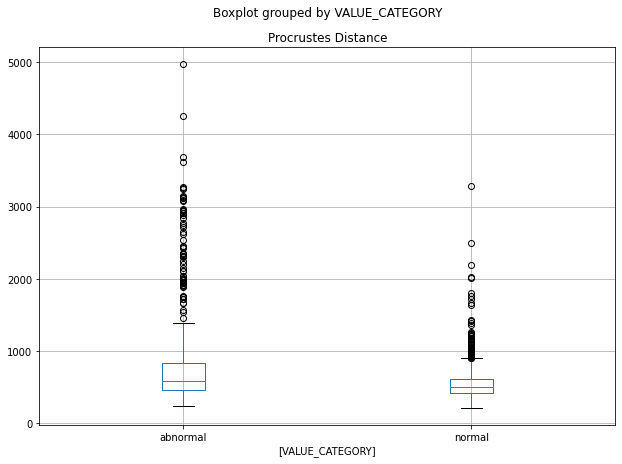

In [141]:
labels[['Procrustes Distance','VALUE_CATEGORY']].dropna().loc[labels['Procrustes Distance']<5000].boxplot(by='VALUE_CATEGORY',figsize=(10,7))

In [142]:
model_for = labels[['percentage of 99%','VALUE_CATEGORY']].loc[labels['Procrustes Distance']<5000]
model_for = model_for.dropna()
x = np.linspace(0.02,1,100).tolist()
true_p = []
all_p = []
all_neg = []
true_neg = []
for frob in x: 
    
    tmp_ab = model_for.loc[model_for['percentage of 99%'] >= frob ]
    t_all_pos = len(tmp_ab) #all detected positives(as abnormals) 
    t_true_pos = len(tmp_ab.loc[tmp_ab['VALUE_CATEGORY']=='abnormal']) # correctly identified
    tmp_ab = model_for.loc[model_for['percentage of 99%'] < frob ]
    t_true_neg = len(tmp_ab.loc[tmp_ab['VALUE_CATEGORY']=='normal'])
    t_all_neg = len(tmp_ab)
    true_p.append(t_true_pos)
    all_p.append(t_all_pos)
    all_neg.append(t_all_neg)
    true_neg.append(t_true_neg)
#    break
model_for = pd.DataFrame()
model_for['tp'] = true_p
model_for['ap'] = all_p
model_for['an'] = all_neg
model_for['tn'] = true_neg
model_for['sensitivity'] = model_for['tp'] / model_for['ap']
model_for['specificity'] = model_for['tn'] / model_for['an']
model_for['accuracy'] = (model_for['tp'] +model_for['tn']) / (model_for['an'] + model_for['ap'])
model_for.index = x

<AxesSubplot:>

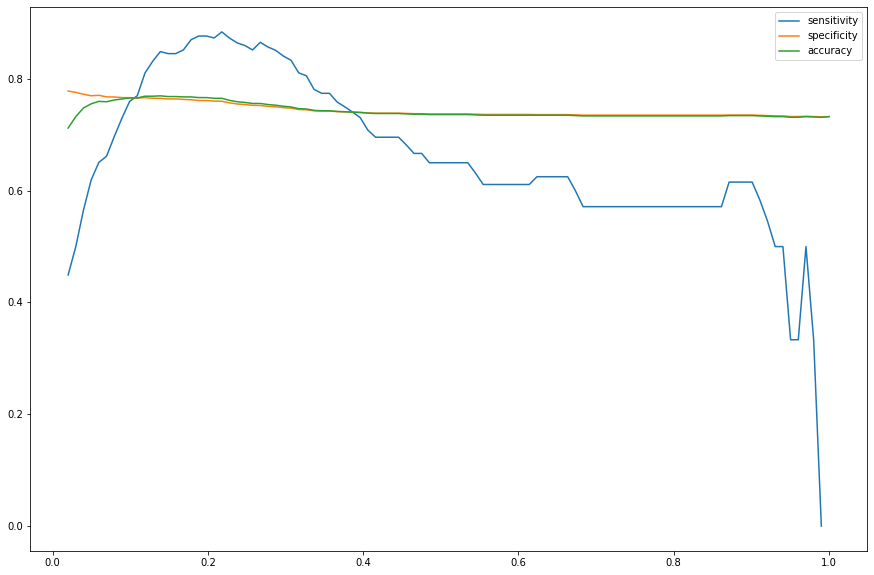

In [143]:
model_for[['sensitivity','specificity','accuracy']].plot(figsize=(15,10))

In [144]:
model_for

,tp,ap,an,tn,sensitivity,specificity,accuracy
0.020000,146,325,1290,1004,0.449231,0.778295,0.712074
0.029899,127,254,1361,1056,0.500000,0.775900,0.732508
0.039798,108,191,1424,1100,0.565445,0.772472,0.747988
0.049697,96,155,1460,1124,0.619355,0.769863,0.755418
0.059596,95,146,1469,1132,0.650685,0.770592,0.759752
...,...,...,...,...,...,...,...
0.960404,2,6,1609,1179,0.333333,0.732753,0.731269
0.970303,2,4,1611,1181,0.500000,0.733085,0.732508
0.980202,1,3,1612,1181,0.333333,0.732630,0.731889
0.990101,0,2,1613,1181,0.000000,0.732176,0.731269
